Connected to Python 3.14.0

In [21]:
%matplotlib inline
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [22]:
# Load the dataset
try:
    df = pd.read_csv("data/sweep_results.csv")
    df['pdr_percent'] = df['pdr'] * 100
    print("Data loaded successfully!")
    display(df.head()) # Preview the first few rows in Jupyter
except FileNotFoundError:
    print("Error: Could not find 'sweep_results.csv'. Please check the path.")

Data loaded successfully!


,protocol,sensing_error,ho_period,handovers,tx,rx,pdr,delay_ms,jitter_ms,throughput_kbps,lost,route_lifetime_s,reroute_per_s,ctrl_pkts_per_s,pdr_percent
0,olsr,4.0,30.0,4,142822,129635,0.907668,2.65618,0.000904,9091.73,13187,11.8,0.075,0.0,90.7668
1,delay_opt,4.0,30.0,4,142822,142817,0.999965,0.48069,0.000045,10016.20,5,118.0,0.000,0.0,99.9965
2,ucraan,4.0,30.0,4,142822,142817,0.999965,0.48069,0.000045,10016.20,5,118.0,0.000,0.0,99.9965
3,olsr,4.5,30.0,4,142822,129635,0.907668,2.65618,0.000904,9091.73,13187,11.8,0.075,0.0,90.7668
4,delay_opt,4.5,30.0,4,142822,142817,0.999965,0.48069,0.000045,10016.20,5,118.0,0.000,0.0,99.9965


In [23]:
# Set a clean, academic style for the plots
sns.set_theme(style="whitegrid", context="talk", font_scale=0.9)

In [24]:
# Standardized colors and labels for consistency across all plots
colors = {"olsr": "#95a5a6", "delay_opt": "#e74c3c", "ucraan": "#2ecc71"}
labels = {"olsr": "OLSR (Baseline)", "delay_opt": "Delay-Optimal", "ucraan": "UCRAAN (Proposed)"}

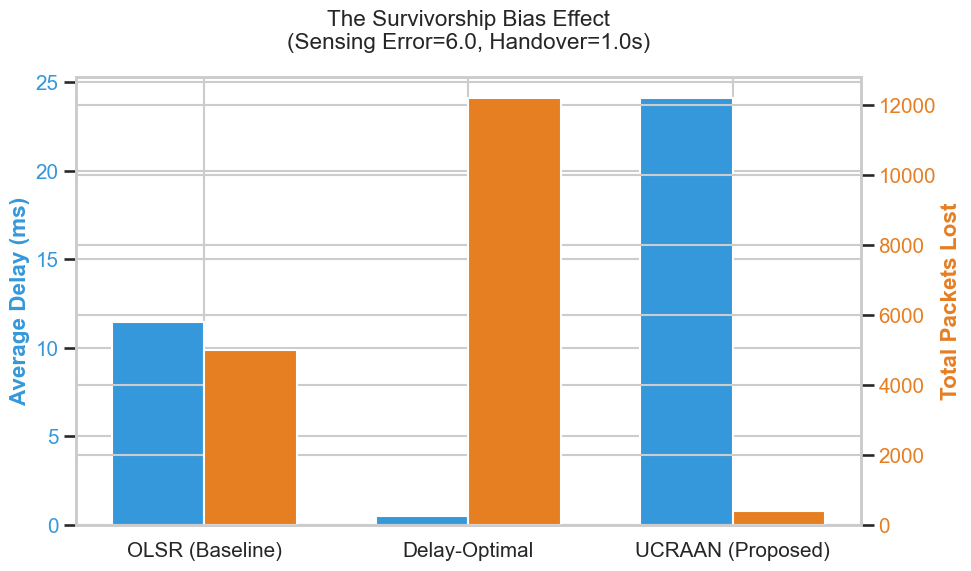

In [30]:
def plot_survivorship_bias(data, ho_target=1.0, se_target=6.0):
    subset = data[(data['ho_period'] == ho_target) & (data['sensing_error'] == se_target)]
    
    fig, ax1 = plt.subplots(figsize=(10, 6))
    x = np.arange(len(subset['protocol']))
    width = 0.35

    # Bar 1: Average Delay
    ax1.bar(x - width/2, subset['delay_ms'], width, color='#3498db', label='Avg Delay (ms)')
    ax1.set_ylabel('Average Delay (ms)', color='#3498db', fontweight='bold')
    ax1.tick_params(axis='y', labelcolor='#3498db')
    ax1.set_xticks(x)
    ax1.set_xticklabels([labels[p] for p in subset['protocol']])

    # Bar 2: Lost Packets
    ax2 = ax1.twinx()
    ax2.bar(x + width/2, subset['lost'], width, color='#e67e22', label='Packets Lost')
    ax2.set_ylabel('Total Packets Lost', color='#e67e22', fontweight='bold')
    ax2.tick_params(axis='y', labelcolor='#e67e22')

    plt.title(f'The Survivorship Bias Effect\n(Sensing Error={se_target}, Handover={ho_target}s)', pad=20)
    fig.tight_layout()
    plt.show()

# Execute Plot 1
plot_survivorship_bias(df, ho_target=1.0, se_target=6.0)

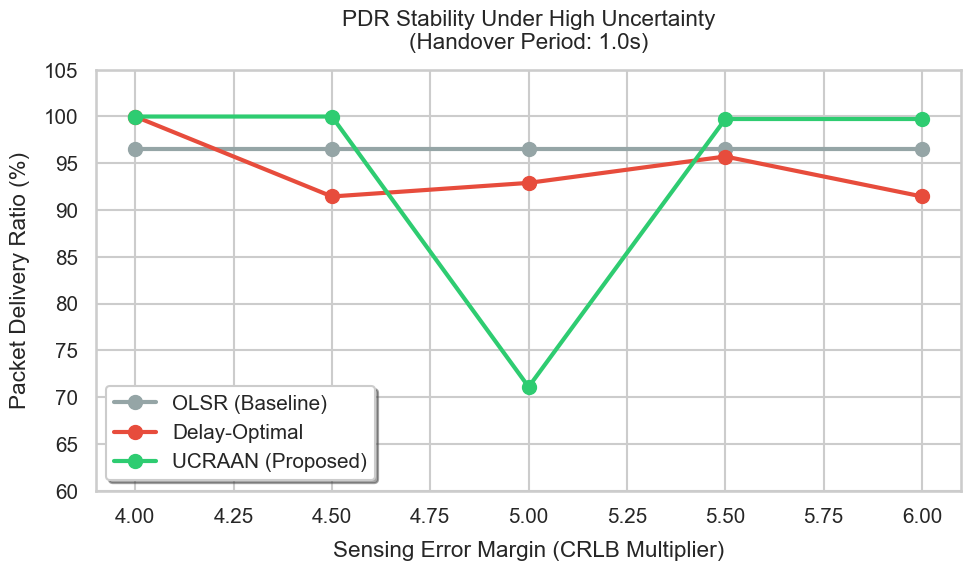

In [31]:
def plot_pdr_vs_noise(data, ho_target=1.0):
    subset = data[data['ho_period'] == ho_target]
    
    plt.figure(figsize=(10, 6))
    for protocol in ['olsr', 'delay_opt', 'ucraan']:
        proto_data = subset[subset['protocol'] == protocol]
        plt.plot(proto_data['sensing_error'], proto_data['pdr_percent'], 
                 marker='o', linewidth=3, markersize=10,
                 color=colors[protocol], label=labels[protocol])

    plt.xlabel('Sensing Error Margin (CRLB Multiplier)', labelpad=10)
    plt.ylabel('Packet Delivery Ratio (%)', labelpad=10)
    plt.title(f'PDR Stability Under High Uncertainty\n(Handover Period: {ho_target}s)', pad=15)
    
    # Cap the Y-axis to clearly show the contrast between the protocols
    plt.ylim(60, 105) 
    plt.legend(loc='lower left', frameon=True, shadow=True)
    
    plt.tight_layout()
    plt.show()

# Execute Plot 2
plot_pdr_vs_noise(df, ho_target=1.0)

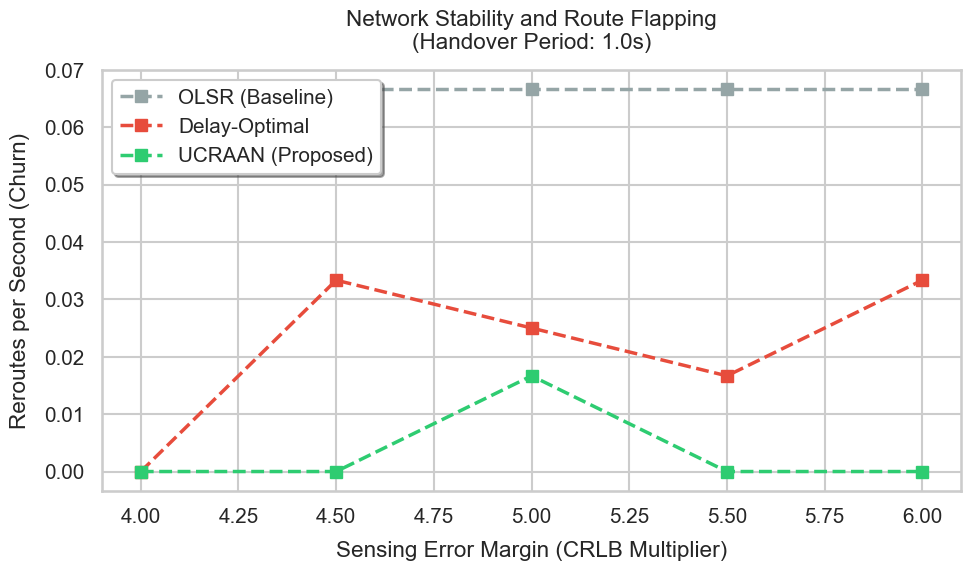

In [33]:
def plot_routing_churn(data, ho_target=1.0):
    subset = data[data['ho_period'] == ho_target]
    
    plt.figure(figsize=(10, 6))
    for protocol in ['olsr', 'delay_opt', 'ucraan']:
        proto_data = subset[subset['protocol'] == protocol]
        plt.plot(proto_data['sensing_error'], proto_data['reroute_per_s'], 
                 marker='s', linewidth=2.5, markersize=8, linestyle='--',
                 color=colors[protocol], label=labels[protocol])

    plt.xlabel('Sensing Error Margin (CRLB Multiplier)', labelpad=10)
    plt.ylabel('Reroutes per Second (Churn)', labelpad=10)
    plt.title(f'Network Stability and Route Flapping\n(Handover Period: {ho_target}s)', pad=15)
    
    plt.legend(loc='upper left', frameon=True, shadow=True)
    plt.tight_layout()
    plt.show()

# Execute Plot 3
plot_routing_churn(df, ho_target=1.0)